In [4]:
%pip install numpy pandas matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")


Libraries imported successfully!


In [8]:
import pandas as pd
from IPython.display import display

file_path = "C:/Users/ADMIN/Downloads/climate_change_analysis_synthetic_20000_rows.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())

Dataset loaded successfully!
Rows: 20000
Columns: 17


,record_id,date,year,month,country,region,avg_temperature_c,co2_concentration_ppm,co2_emissions_per_capita_tonnes,sea_level_change_mm_since_1980,precipitation_mm,renewable_energy_share_pct,forest_loss_hectares_est,extreme_weather_events_est,population_millions_est,energy_use_index_est,drought_index_est
0,1,1981-11-03,1981,11,United States,North America,7.54,340.66,12.69,6.55,74.54,7.82,1509.49,0,367.64,18.10,-1.407
1,2,2013-09-10,2013,9,Pakistan,Asia,11.19,405.70,1.37,116.86,64.81,18.43,688.39,4,1353.59,1.31,-2.070
2,3,1989-03-21,1989,3,Russia,Europe/Asia,1.83,356.78,10.12,29.95,146.32,3.48,NaN,1,108.74,8.20,1.165
3,4,2012-12-12,2012,12,Japan,Asia,11.61,406.52,9.59,103.71,42.01,12.37,1093.71,1,789.65,11.71,-0.483
4,5,2005-12-05,2005,12,Japan,Asia,9.48,390.24,8.28,81.28,169.62,19.28,210.05,1,421.54,10.11,-0.401


In [9]:
print("Dataset dimensions:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types and non-null counts:")
df.info()

Dataset dimensions: (20000, 17)

Column names:
['record_id', 'date', 'year', 'month', 'country', 'region', 'avg_temperature_c', 'co2_concentration_ppm', 'co2_emissions_per_capita_tonnes', 'sea_level_change_mm_since_1980', 'precipitation_mm', 'renewable_energy_share_pct', 'forest_loss_hectares_est', 'extreme_weather_events_est', 'population_millions_est', 'energy_use_index_est', 'drought_index_est']

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 17 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   record_id                        20000 non-null  int64  
 1   date                             20000 non-null  str    
 2   year                             20000 non-null  int64  
 3   month                            20000 non-null  int64  
 4   country                          20000 non-null  str    
 5   region                      

In [10]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
record_id,20000.0,NaN,NaN,NaN,10000.5,5773.647028,1.0,5000.75,10000.5,15000.25,20000.0
date,20000,11260,2004-06-13,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,20000.0,NaN,NaN,NaN,2002.57945,13.313829,1980.0,1991.0,2003.0,2014.0,2025.0
month,20000.0,NaN,NaN,NaN,6.51175,3.445208,1.0,4.0,7.0,10.0,12.0
country,20000,20,Indonesia,1050,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,20000,7,Asia,6105,NaN,NaN,NaN,NaN,NaN,NaN,NaN
avg_temperature_c,19779.0,NaN,NaN,NaN,15.436035,10.099079,-15.61,8.5,16.6,23.15,39.59
co2_concentration_ppm,20000.0,NaN,NaN,NaN,384.265693,27.35739,332.96,360.5,384.535,407.91,435.08
co2_emissions_per_capita_tonnes,20000.0,NaN,NaN,NaN,6.803439,5.277783,0.24,2.15,6.19,10.09,25.77
sea_level_change_mm_since_1980,20000.0,NaN,NaN,NaN,76.751557,46.05781,-26.13,37.515,76.965,116.0625,177.49


In [11]:
print("Duplicate rows:", df.duplicated().sum())
print("\nMissing values by column:")
missing = df.isna().sum().sort_values(ascending=False)
display(missing[missing > 0].to_frame("missing_count"))

Duplicate rows: 0

Missing values by column:


,missing_count
precipitation_mm,277
forest_loss_hectares_est,229
renewable_energy_share_pct,227
avg_temperature_c,221


In [12]:
# Convert date to a proper datetime type.
df["date"] = pd.to_datetime(df["date"], errors="coerce")

# Remove duplicate rows if any.
df = df.drop_duplicates().copy()

# Add convenient time features.
df["year"] = pd.to_numeric(df["year"], errors="coerce")
df["month"] = pd.to_numeric(df["month"], errors="coerce")

print("After removing duplicates:", df.shape)

After removing duplicates: (20000, 17)


In [13]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()
categorical_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()

for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

for col in categorical_cols:
    if df[col].isna().any():
        mode_values = df[col].mode()
        if not mode_values.empty:
            df[col] = df[col].fillna(mode_values.iloc[0])

print("Missing values remaining:", int(df.isna().sum().sum()))

Missing values remaining: 0


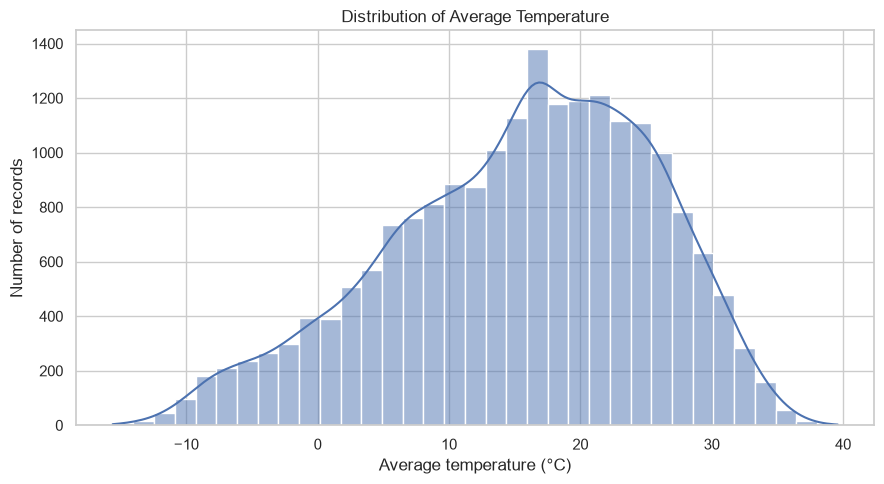

In [14]:
# Distribution of average temperature
plt.figure(figsize=(9, 5))
sns.histplot(df["avg_temperature_c"], bins=35, kde=True)
plt.title("Distribution of Average Temperature")
plt.xlabel("Average temperature (°C)")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

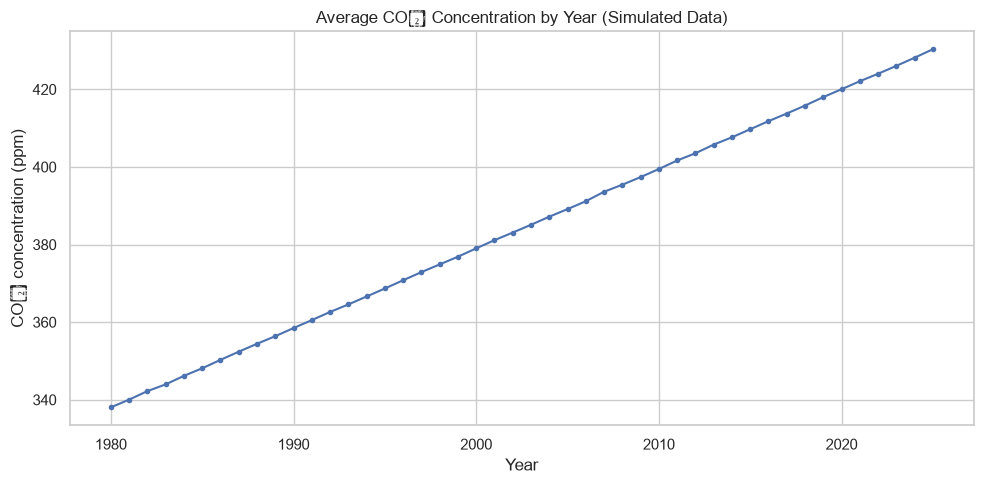

,year,avg_temperature_c,co2_concentration_ppm,sea_level_change_mm_since_1980,renewable_energy_share_pct
0,1980,15.105933,338.036178,-0.055133,16.778578
1,1981,14.385728,340.033908,3.296044,17.056699
2,1982,15.001416,342.220310,7.120553,17.027611
3,1983,15.132512,343.958582,10.028085,16.989204
4,1984,14.385717,346.155314,13.598610,17.577422


In [15]:
# CO2 concentration over time (mean by year)
yearly = df.groupby("year", as_index=False).agg(
    avg_temperature_c=("avg_temperature_c", "mean"),
    co2_concentration_ppm=("co2_concentration_ppm", "mean"),
    sea_level_change_mm_since_1980=("sea_level_change_mm_since_1980", "mean"),
    renewable_energy_share_pct=("renewable_energy_share_pct", "mean")
)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(yearly["year"], yearly["co2_concentration_ppm"], marker=".", linewidth=1.5)
ax.set_title("Average CO₂ Concentration by Year (Simulated Data)")
ax.set_xlabel("Year")
ax.set_ylabel("CO₂ concentration (ppm)")
plt.tight_layout()
plt.show()

display(yearly.head())

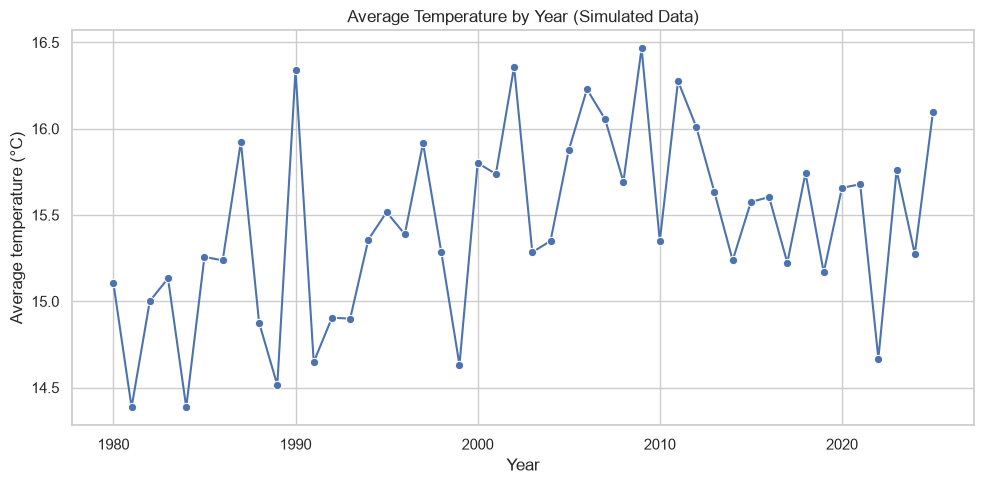

In [16]:
# Average temperature by year
plt.figure(figsize=(10, 5))
sns.lineplot(data=yearly, x="year", y="avg_temperature_c", marker="o")
plt.title("Average Temperature by Year (Simulated Data)")
plt.xlabel("Year")
plt.ylabel("Average temperature (°C)")
plt.tight_layout()
plt.show()

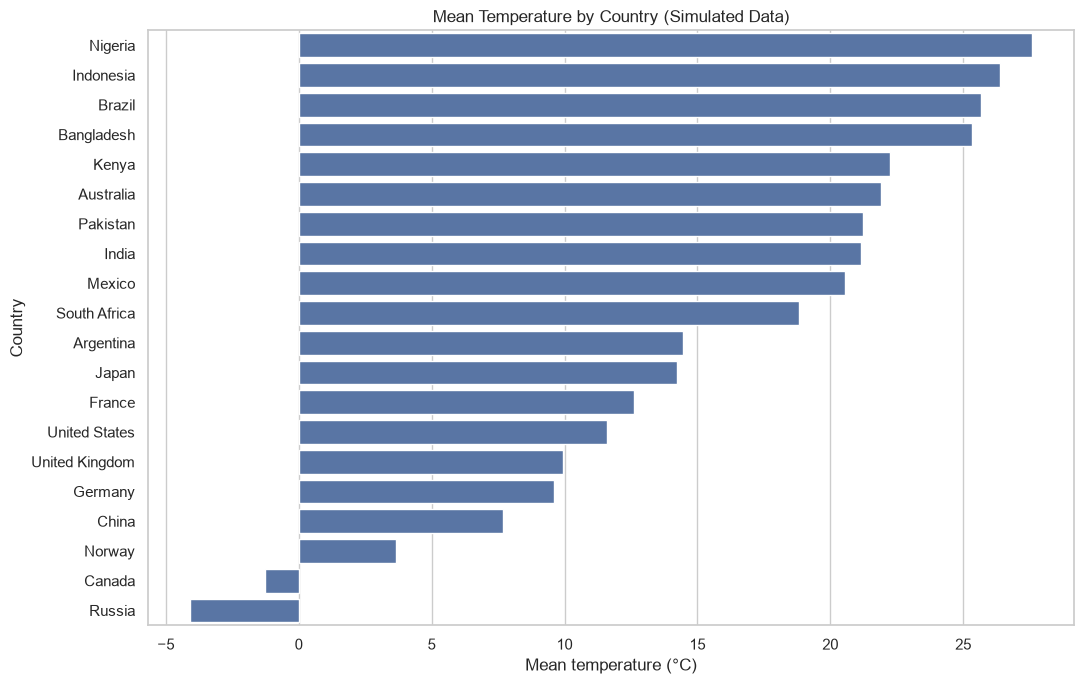

,country,avg_temperature_c
13,Nigeria,27.587013
9,Indonesia,26.376143
3,Brazil,25.670474
2,Bangladesh,25.335825
11,Kenya,22.255228
1,Australia,21.904688
15,Pakistan,21.224177
8,India,21.170567
12,Mexico,20.560306
17,South Africa,18.818943


In [17]:
# Compare countries by average temperature
country_temp = (df.groupby("country", as_index=False)["avg_temperature_c"]
                  .mean()
                  .sort_values("avg_temperature_c", ascending=False))

plt.figure(figsize=(11, 7))
sns.barplot(data=country_temp, x="avg_temperature_c", y="country")
plt.title("Mean Temperature by Country (Simulated Data)")
plt.xlabel("Mean temperature (°C)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

display(country_temp)

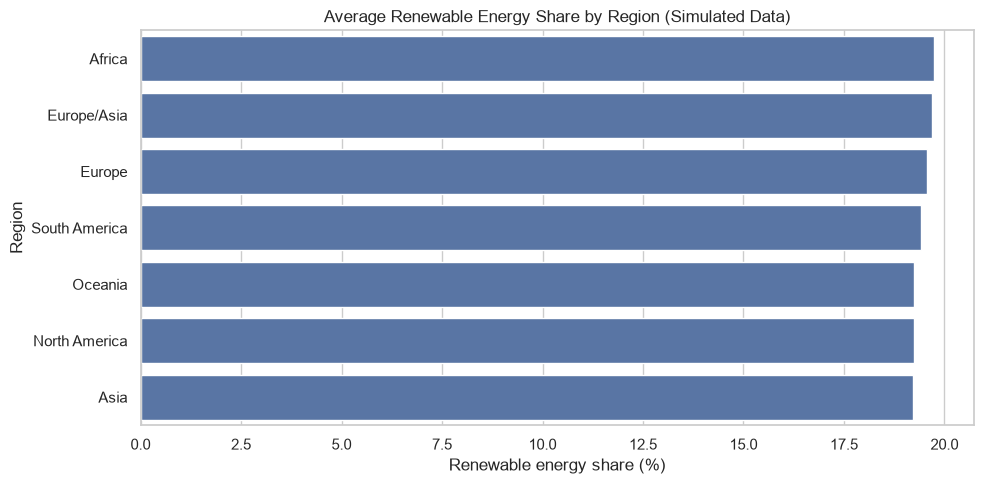

In [18]:
# Renewable energy share by region
region_renewable = (df.groupby("region", as_index=False)["renewable_energy_share_pct"]
                      .mean()
                      .sort_values("renewable_energy_share_pct", ascending=False))

plt.figure(figsize=(10, 5))
sns.barplot(data=region_renewable, x="renewable_energy_share_pct", y="region")
plt.title("Average Renewable Energy Share by Region (Simulated Data)")
plt.xlabel("Renewable energy share (%)")
plt.ylabel("Region")
plt.tight_layout()
plt.show()

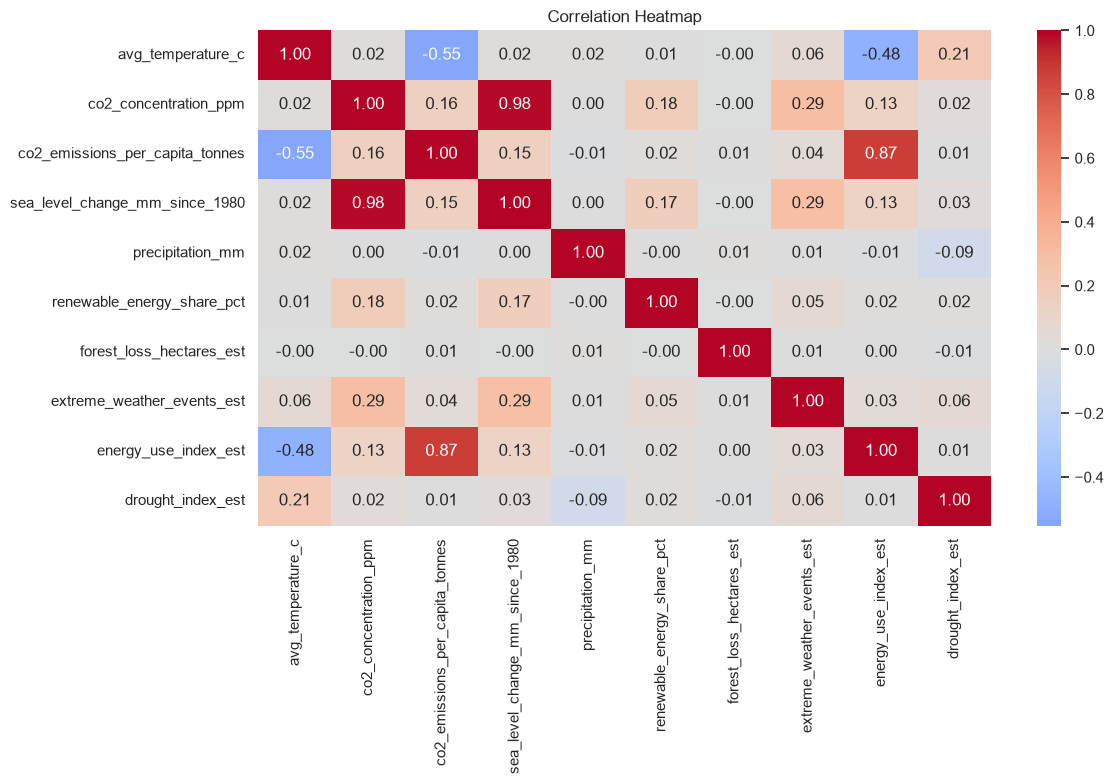

,correlation_with_temperature
avg_temperature_c,1.000000
drought_index_est,0.209257
extreme_weather_events_est,0.057834
sea_level_change_mm_since_1980,0.022993
co2_concentration_ppm,0.021092
precipitation_mm,0.019403
renewable_energy_share_pct,0.010501
forest_loss_hectares_est,-0.004332
energy_use_index_est,-0.479329
co2_emissions_per_capita_tonnes,-0.552759


In [19]:
#correlation analysis
numeric_for_corr = [
    "avg_temperature_c",
    "co2_concentration_ppm",
    "co2_emissions_per_capita_tonnes",
    "sea_level_change_mm_since_1980",
    "precipitation_mm",
    "renewable_energy_share_pct",
    "forest_loss_hectares_est",
    "extreme_weather_events_est",
    "energy_use_index_est",
    "drought_index_est"
]
corr = df[numeric_for_corr].corr(numeric_only=True)

plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

display(corr["avg_temperature_c"].sort_values(ascending=False).to_frame("correlation_with_temperature"))

In [20]:
#Compare selected indicators across countries
country_summary = df.groupby("country").agg(
    records=("record_id", "count"),
    mean_temperature_c=("avg_temperature_c", "mean"),
    mean_co2_emissions_per_capita=("co2_emissions_per_capita_tonnes", "mean"),
    mean_renewable_share_pct=("renewable_energy_share_pct", "mean"),
    mean_forest_loss_hectares=("forest_loss_hectares_est", "mean"),
    mean_extreme_weather_events=("extreme_weather_events_est", "mean")
).round(2).sort_values("mean_co2_emissions_per_capita", ascending=False)

display(country_summary)

,records,mean_temperature_c,mean_co2_emissions_per_capita,mean_renewable_share_pct,mean_forest_loss_hectares,mean_extreme_weather_events
country,,,,,,
Australia,1009,21.90,16.56,19.25,2430.98,1.27
Canada,1023,-1.25,15.50,19.38,2378.24,1.26
United States,970,11.61,15.48,18.97,2396.20,1.25
Russia,992,-4.07,11.44,19.69,2366.74,1.24
Germany,960,9.59,10.37,19.34,2460.20,1.32
Japan,1036,14.22,9.35,19.15,2438.74,1.31
South Africa,974,18.82,8.87,19.70,2491.68,1.24
Norway,1000,3.67,8.34,19.77,2324.59,1.24
United Kingdom,1023,9.95,8.29,19.24,2377.29,1.17


In [21]:
#Simple machine-learning model
target = "avg_temperature_c"
features = [
    "year", "month", "country", "region",
    "co2_concentration_ppm",
    "co2_emissions_per_capita_tonnes",
    "sea_level_change_mm_since_1980",
    "precipitation_mm",
    "renewable_energy_share_pct",
    "forest_loss_hectares_est",
    "extreme_weather_events_est",
    "energy_use_index_est",
    "drought_index_est"
]

X = df[features].copy()
y = df[target].copy()

numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model.fit(X_train, y_train)
predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print(f"Mean Absolute Error (MAE): {mae:.3f} °C")
print(f"Root Mean Squared Error (RMSE): {rmse:.3f} °C")
print(f"R² score: {r2:.3f}")

Mean Absolute Error (MAE): 1.830 °C
Root Mean Squared Error (RMSE): 2.446 °C
R² score: 0.942


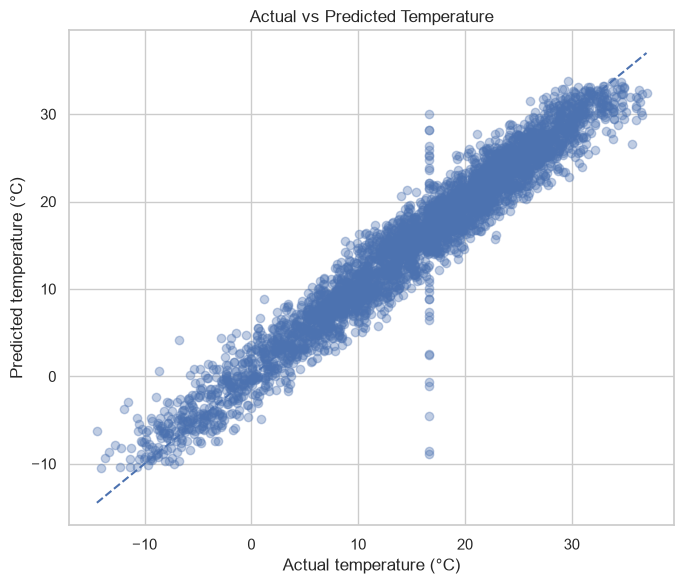

In [22]:
# Actual vs predicted temperatures
plt.figure(figsize=(7, 6))
plt.scatter(y_test, predictions, alpha=0.35)
low = min(y_test.min(), predictions.min())
high = max(y_test.max(), predictions.max())
plt.plot([low, high], [low, high], linestyle="--")
plt.title("Actual vs Predicted Temperature")
plt.xlabel("Actual temperature (°C)")
plt.ylabel("Predicted temperature (°C)")
plt.tight_layout()
plt.show()

In [23]:
#Try a prediction for a new example
#Change the values below if you want to test another example. Country and region names must be consistent with the dataset.
new_observation = pd.DataFrame([{
    "year": 2025,
    "month": 7,
    "country": "India",
    "region": "Asia",
    "co2_concentration_ppm": 430.0,
    "co2_emissions_per_capita_tonnes": 2.2,
    "sea_level_change_mm_since_1980": 150.0,
    "precipitation_mm": 100.0,
    "renewable_energy_share_pct": 25.0,
    "forest_loss_hectares_est": 1500.0,
    "extreme_weather_events_est": 2,
    "energy_use_index_est": 4.0,
    "drought_index_est": 0.2
}])

predicted_temp = model.predict(new_observation)[0]
print(f"Predicted temperature (model demonstration): {predicted_temp:.2f} °C")
print("Reminder: this is a prediction from simulated practice data, not an official forecast.")

Predicted temperature (model demonstration): 22.26 °C
Reminder: this is a prediction from simulated practice data, not an official forecast.


In [24]:
#Export cleaned data and summary tables
df.to_csv("climate_change_cleaned.csv", index=False)
yearly.to_csv("yearly_climate_summary.csv", index=False)
country_summary.to_csv("country_climate_summary.csv")

print("Saved files:")
print("- climate_change_cleaned.csv")
print("- yearly_climate_summary.csv")
print("- country_climate_summary.csv")

Saved files:
- climate_change_cleaned.csv
- yearly_climate_summary.csv
- country_climate_summary.csv
